# Этап 1. Знакомство с данными

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

print("Библиотеки загружены")

Библиотеки загружены


In [ ]:
df = pd.read_csv('../data/raw_data/cookie_cats.csv')

print("Размер:", df.shape)
print("Колонки:", df.columns.tolist())
print()
df.info()

Размер: (90189, 5)
Колонки: ['userid', 'version', 'sum_gamerounds', 'retention_1', 'retention_7']

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.2 MB


In [ ]:
print("Пропуски:")
print(df.isnull().sum())
print()

print("Дубли по userid:")
print(df['userid'].duplicated().sum())
print()

print("Уникальных пользователей:", df['userid'].nunique())
print("Всего строк:", len(df))

Пропуски:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

Дубли по userid:
0

Уникальных пользователей: 90189
Всего строк: 90189


In [ ]:
print("Версии приложения:")
print(df['version'].value_counts())
print()

print("Retention 1 день:")
print(df['retention_1'].value_counts())
print()

print("Retention 7 дней:")
print(df['retention_7'].value_counts())

Версии приложения:
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

Retention 1 день:
retention_1
False    50036
True     40153
Name: count, dtype: int64

Retention 7 дней:
retention_7
False    73408
True     16781
Name: count, dtype: int64


In [ ]:
print(df['sum_gamerounds'].describe())
print()
print("Медиана:", df['sum_gamerounds'].median())
print("Максимум:", df['sum_gamerounds'].max())
print("Минимум:", df['sum_gamerounds'].min())

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

Медиана: 16.0
Максимум: 49854
Минимум: 0


In [ ]:
summary = df.groupby('version').agg(
    users=('userid', 'count'),
    avg_gamerounds=('sum_gamerounds', 'mean'),
    median_gamerounds=('sum_gamerounds', 'median'),
    retention_1_rate=('retention_1', 'mean'),
    retention_7_rate=('retention_7', 'mean')
).round(4)

print(summary)

         users  avg_gamerounds  median_gamerounds  retention_1_rate  retention_7_rate
version                                                                              
gate_30  44700         52.4563               17.0            0.4482            0.1902
gate_40  45489         51.2988               16.0            0.4423            0.1820


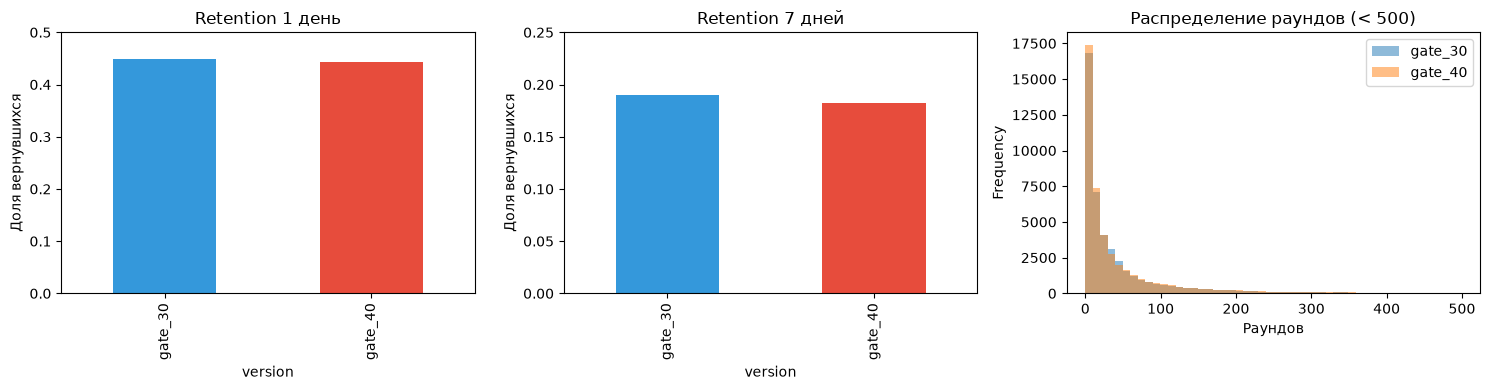

Сохранено: 01_overview.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Retention 1
df.groupby('version')['retention_1'].mean().plot(
    kind='bar', ax=axes[0], color=['#3498db', '#e74c3c']
)
axes[0].set_title('Retention 1 день')
axes[0].set_ylabel('Доля вернувшихся')
axes[0].set_ylim(0, 0.5)

# Retention 7
df.groupby('version')['retention_7'].mean().plot(
    kind='bar', ax=axes[1], color=['#3498db', '#e74c3c']
)
axes[1].set_title('Retention 7 дней')
axes[1].set_ylabel('Доля вернувшихся')
axes[1].set_ylim(0, 0.25)

# Распределение sum_gamerounds (log scale)
df[df['sum_gamerounds'] < 500].groupby('version')['sum_gamerounds'].plot(
    kind='hist', bins=50, alpha=0.5, ax=axes[2], legend=True
)
axes[2].set_title('Распределение раундов (< 500)')
axes[2].set_xlabel('Раундов')

plt.tight_layout()
plt.savefig('../data/processed_data/01_overview.png', dpi=100, bbox_inches='tight')
plt.show()

print("Сохранено: 01_overview.png")

1. Размеры групп различаются.

gate_30 = 44 700, gate_40 = 45 489. Разница — 789 человек (1,75%).

In [ ]:
# 1. Размеры групп и SRM
print("=== 1. РАЗМЕРЫ ГРУПП ===")
print()

group_sizes = df['version'].value_counts().sort_index()
print(group_sizes)
print()

total = len(df)
gate_30 = group_sizes['gate_30']
gate_40 = group_sizes['gate_40']

print(f"Всего пользователей: {total:,}")
print(f"gate_30: {gate_30:,} ({gate_30 / total:.4%})")
print(f"gate_40: {gate_40:,} ({gate_40 / total:.4%})")
print()

diff = abs(gate_40 - gate_30)
print(f"Разница: {diff:,} человек")
print(f"Относительная разница: {diff / total:.4%}")
print()

# Проверка: ожидаемое соотношение 50/50
expected = total / 2
print(f"Ожидалось бы (50/50): {expected:,.0f} на группу")
print(f"Отклонение gate_30 от ожидаемого: {gate_30 - expected:+,.0f}")
print(f"Отклонение gate_40 от ожидаемого: {gate_40 - expected:+,.0f}")

=== 1. РАЗМЕРЫ ГРУПП ===

version
gate_30    44700
gate_40    45489
Name: count, dtype: int64

Всего пользователей: 90,189
gate_30: 44,700 (49.5626%)
gate_40: 45,489 (50.4374%)

Разница: 789 человек
Относительная разница: 0.8748%

Ожидалось бы (50/50): 45,094 на группу
Отклонение gate_30 от ожидаемого: -394
Отклонение gate_40 от ожидаемого: +394


# SRM-тест: значимо ли отклонение от 50/50?

In [ ]:
from scipy.stats import chisquare

print("=== SRM-ТЕСТ ===")
print()

observed = [gate_30, gate_40]
expected_counts = [total / 2, total / 2]

chi2, p_value = chisquare(observed, expected_counts)

print(f"Наблюдаемые: {observed}")
print(f"Ожидаемые:   {expected_counts}")
print()
print(f"Chi-square: {chi2:.4f}")
print(f"p-value: {p_value:.4f}")
print()

if p_value < 0.05:
    print("SRM обнаружен: отклонение значимо (p < 0.05)")
    print("Рандомизация могла быть нарушена.")
else:
    print("SRM не обнаружен: отклонение незначимо (p >= 0.05)")
    print("Распределение групп соответствует ожидаемому 50/50.")

=== SRM-ТЕСТ ===

Наблюдаемые: [np.int64(44700), np.int64(45489)]
Ожидаемые:   [45094.5, 45094.5]

Chi-square: 6.9024
p-value: 0.0086

SRM обнаружен: отклонение значимо (p < 0.05)
Рандомизация могла быть нарушена.


2. Аномалия в sum_gamerounds.
Максимум = 49 854 раунда. Средний = 52. Это выброс — один игрок провёл в игре аномально много времени.

In [ ]:
# 3. Аномалия в sum_gamerounds
print("=== 2. АНОМАЛИЯ В sum_gamerounds ===")
print()

print(f"Среднее: {df['sum_gamerounds'].mean():.2f}")
print(f"Медиана: {df['sum_gamerounds'].median():.2f}")
print(f"Максимум: {df['sum_gamerounds'].max():,}")
print(f"Минимум: {df['sum_gamerounds'].min()}")
print()

# Топ-10 игроков по числу раундов
print("Топ-10 по числу раундов:")
print(df.nlargest(10, 'sum_gamerounds')[['userid', 'version', 'sum_gamerounds', 'retention_1', 'retention_7']])
print()

# Сколько игроков с аномально большим числом раундов
threshold = 1000
anomalies = df[df['sum_gamerounds'] > threshold]
print(f"Игроков с > {threshold} раундов: {len(anomalies)} ({len(anomalies) / len(df):.4%})")
print()

# 99-й перцентиль
p99 = df['sum_gamerounds'].quantile(0.99)
p999 = df['sum_gamerounds'].quantile(0.999)
print(f"99-й перцентиль: {p99:.0f} раундов")
print(f"99.9-й перцентиль: {p999:.0f} раундов")
print()

# Какую долю от общего числа раундов дают топ-1%?
top1 = df.nlargest(int(len(df) * 0.01), 'sum_gamerounds')['sum_gamerounds'].sum()
total_rounds = df['sum_gamerounds'].sum()
print(f"Топ-1% игроков дают {top1 / total_rounds:.2%} всех раундов")

=== 2. АНОМАЛИЯ В sum_gamerounds ===

Среднее: 51.87
Медиана: 16.00
Максимум: 49,854
Минимум: 0

Топ-10 по числу раундов:
        userid  version  sum_gamerounds  retention_1  retention_7
57702  6390605  gate_30           49854        False         True
7912    871500  gate_30            2961         True         True
29417  3271615  gate_40            2640         True        False
43671  4832608  gate_30            2438         True         True
48188  5346171  gate_40            2294         True         True
46344  5133952  gate_30            2251         True         True
87007  9640085  gate_30            2156         True         True
36933  4090246  gate_40            2124         True         True
88328  9791599  gate_40            2063         True         True
6536    725080  gate_40            2015         True         True

Игроков с > 1000 раундов: 116 (0.1286%)

99-й перцентиль: 493 раундов
99.9-й перцентиль: 1074 раундов

Топ-1% игроков дают 15.04% всех раундов


3. Распределение сильно скошено.
Среднее = 52, медиана = 16. Это значит, что большинство играет мало, но есть «киты», которые тянут среднее вверх.

=== 3. СКОШЕННОСТЬ РАСПРЕДЕЛЕНИЯ ===

Среднее: 51.87
Медиана: 16.00
Разница: 35.87

Skewness (асимметрия): 185.43
  (>1 — сильная правосторонняя асимметрия)

Kurtosis (эксцесс): 47127.76
  (>3 — тяжёлые хвосты)

Квантили:
  25%: 5
  50%: 16
  75%: 51
  90%: 134
  95%: 221
  99%: 493



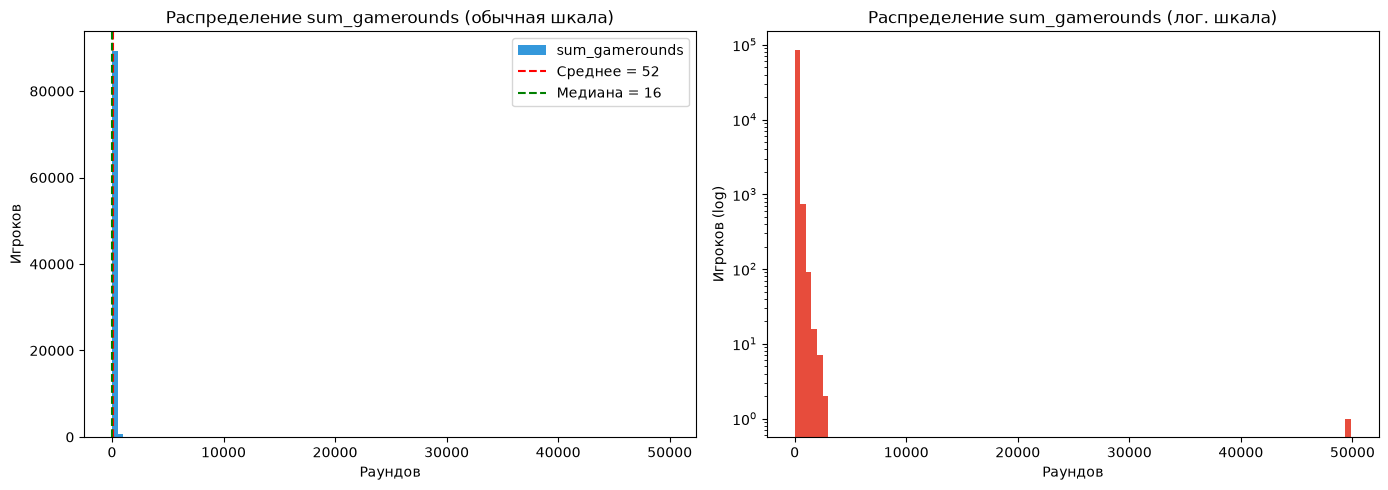

Сохранено: 01_distribution.png


In [ ]:
from scipy.stats import skew, kurtosis

print("=== 3. СКОШЕННОСТЬ РАСПРЕДЕЛЕНИЯ ===")
print()

print(f"Среднее: {df['sum_gamerounds'].mean():.2f}")
print(f"Медиана: {df['sum_gamerounds'].median():.2f}")
print(f"Разница: {df['sum_gamerounds'].mean() - df['sum_gamerounds'].median():.2f}")
print()

# Коэффициент асимметрии
sk = skew(df['sum_gamerounds'])
print(f"Skewness (асимметрия): {sk:.2f}")
print("  (>1 — сильная правосторонняя асимметрия)")
print()

# Куртозис
kurt = kurtosis(df['sum_gamerounds'])
print(f"Kurtosis (эксцесс): {kurt:.2f}")
print("  (>3 — тяжёлые хвосты)")
print()

# Квантили
print("Квантили:")
for q in [0.25, 0.5, 0.75, 0.9, 0.95, 0.99]:
    print(f"  {q*100:.0f}%: {df['sum_gamerounds'].quantile(q):.0f}")
print()

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Обычная шкала
df['sum_gamerounds'].plot(kind='hist', bins=100, ax=axes[0], color='#3498db')
axes[0].set_title('Распределение sum_gamerounds (обычная шкала)')
axes[0].set_xlabel('Раундов')
axes[0].set_ylabel('Игроков')
axes[0].axvline(df['sum_gamerounds'].mean(), color='red', linestyle='--', 
                label=f"Среднее = {df['sum_gamerounds'].mean():.0f}")
axes[0].axvline(df['sum_gamerounds'].median(), color='green', linestyle='--', 
                label=f"Медиана = {df['sum_gamerounds'].median():.0f}")
axes[0].legend()

# Логарифмическая шкала
df[df['sum_gamerounds'] > 0]['sum_gamerounds'].plot(
    kind='hist', bins=100, ax=axes[1], color='#e74c3c', logy=True
)
axes[1].set_title('Распределение sum_gamerounds (лог. шкала)')
axes[1].set_xlabel('Раундов')
axes[1].set_ylabel('Игроков (log)')

plt.tight_layout()
plt.savefig('../data/processed_data/01_distribution.png', dpi=100, bbox_inches='tight')
plt.show()

print("Сохранено: 01_distribution.png")

# факты кратко:
Куртозис = 47 127 — экстремально высокий. Это значит, что распределение sum_gamerounds имеет очень тяжёлые хвосты
df['sum_gamerounds'].quantile(0.99) = 493 раунда. Это значит, что 99% игроков сыграли меньше 493 раундов.
Skewness = 185,43 — экстремальная правосторонняя асимметрия. Это значит, что большинство игроков играют мало (медиана = 16), но есть единицы, которые играют очень много.